# 03 — BOCPD Analysis

Runs the Bayesian Online Change Point Detection (BOCPD) algorithm on a
sample of 20 PM pairs, plots detected change points, and summarises results.

**Prerequisites**:
- `scripts/generate_queries.py` → `../data/features/competitive_features.csv`
  (or run feature computation inline below)

**Outputs**
- `../data/figures/bocpd_pair_{n}.png`  (3 figures)
- `../data/figures/bocpd_cp_summary.png`

In [1]:
import sys
import os
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import numpy as np

warnings.filterwarnings('ignore')

sys.path.insert(0, '..')

from src.bocpd.config import BOCPDConfig, HazardConfig, NormalGammaConfig
from src.bocpd.detector import run_bocpd_on_catalogue
from src.features.competitive_features import load_competitive_features

os.makedirs('../data/figures', exist_ok=True)

print('Imports OK')

Imports OK


## 1. Load Feature Data

In [2]:
features_path = '../data/features/competitive_features.csv'

try:
    features_df = load_competitive_features(features_path)
    print(f'Loaded competitive features: {features_df.shape[0]:,} rows × {features_df.shape[1]} columns')
    print(f'Columns: {list(features_df.columns)}')
except FileNotFoundError:
    raise FileNotFoundError(
        f'Feature file not found at {features_path}.\n'
        'Run scripts/generate_queries.py (or the full pipeline) to produce this file.'
    )

Loaded competitive features: 33,869 rows × 57 columns
Columns: ['product_id', 'merchant', 'observed_at', 'price', 'price_min', 'price_max', 'is_sale', 'availability', 'condition', 'offer', 'product_name', 'brand', 'manufacturer', 'manufacturer_number', 'category', 'source_url', 'observation_index', 'previous_price', 'absolute_change', 'percentage_change', 'days_since_previous', 'log_price', 'log_price_diff', 'expanding_zscore', 'price_direction', 'cumulative_log_change', 'rolling_mean_3', 'rolling_std_3', 'rolling_median_3', 'rolling_mean_price_3', 'rolling_volatility_3', 'price_deviation_3', 'rolling_mean_5', 'rolling_std_5', 'rolling_median_5', 'rolling_mean_price_5', 'rolling_volatility_5', 'price_deviation_5', 'rolling_mean_10', 'rolling_std_10', 'rolling_median_10', 'rolling_mean_price_10', 'rolling_volatility_10', 'price_deviation_10', 'competitor_count', 'competitor_price_min', 'competitor_price_max', 'competitor_price_mean', 'competitor_price_median', 'price_vs_comp_median', 'p

## 2. Sample 20 PM Pairs & Configure BOCPD

In [3]:
# Count observations per PM pair and select the 20 with the most observations
# (richest signal for interesting change-point patterns)
pm_sizes = (
    features_df
    .groupby(['product_id', 'merchant'])
    .size()
    .rename('n_obs')
    .reset_index()
    .nlargest(20, 'n_obs')
)

print(f'Selected {len(pm_sizes)} PM pairs for BOCPD (top by observation count):')
display(pm_sizes.reset_index(drop=True))

# Filter features to the sample
sample_features = features_df.merge(
    pm_sizes[['product_id', 'merchant']],
    on=['product_id', 'merchant'],
    how='inner'
)
print(f'\nSample features shape: {sample_features.shape}')

Selected 20 PM pairs for BOCPD (top by observation count):


,product_id,merchant,n_obs
0,AVphcCmRLJeJML43a6Mh,Amazon.com,202
1,AVpflKqwLJeJML43_2MI,LG.com,112
2,AVpfpK8KLJeJML43BCuD,Amazon.com,78
3,AVpfAs_-ilAPnD_xS-SU,bhphotovideo.com,57
4,AV1YHuUN-jtxr-f31Ndf,bhphotovideo.com,49
5,AVpe6fRRilAPnD_xQvwN,Amazon.com,48
6,AVqKqTgmQMlgsOJE6bhX,bhphotovideo.com,48
7,AVpfg618LJeJML43-j8w,Microsoft,45
8,AV1YFZVDvKc47QAVgp7V,bhphotovideo.com,44
9,AV1YCh1FvKc47QAVgpNt,bhphotovideo.com,43



Sample features shape: (1083, 57)


In [4]:
# BOCPD configuration
config = BOCPDConfig(
    observation_signal='log_price_diff',
    hazard=HazardConfig(lambda_val=50),        # expect a CP every 50 obs (sensitive)
    model=NormalGammaConfig(
        mu0=0.0,
        kappa0=1.0,
        alpha0=1.0,
        beta0=0.01
    ),
    cp_threshold=0.30,
    min_observations_before_detection=3,
    max_run_length=500,
)
print(config.describe())

BOCPD Configuration
----------------------------------------
  Observation signal   : log_price_diff
  Hazard lambda        : 50 obs/change-point
  Constant hazard h    : 0.020000
  NG prior mu0         : 0.0
  NG prior kappa0      : 1.0
  NG prior alpha0      : 1.0
  NG prior beta0       : 0.01
  CP threshold         : 0.3
  Warm-up obs          : 3
  Max run length       : 500


## 3. Run BOCPD on the 20-Pair Sample

In [5]:
print('Running BOCPD historical online replay on sample ...')
bocpd_results = run_bocpd_on_catalogue(
    features_df=sample_features,
    config=config,
    min_observations=5,
)

if bocpd_results.empty:
    print('WARNING: BOCPD returned no results. Check that log_price_diff is present and non-NaN.')
else:
    total_cp = int(bocpd_results['is_change_point'].sum())
    print(f'BOCPD complete.')
    print(f'  Total observations processed : {len(bocpd_results):,}')
    print(f'  Change-point flags           : {total_cp:,}')
    print(f'  Columns: {list(bocpd_results.columns)}')

Running BOCPD historical online replay on sample ...


BOCPD complete.


  Total observations processed : 551
  Change-point flags           : 3
  Columns: ['product_id', 'merchant', 'observation_index', 'observed_at', 'observation_value', 'cp_probability', 'map_run_length', 'is_change_point']


## 4. Plot Price + CP Probability for 3 Selected Pairs

In [6]:
# Choose the 3 pairs with the most detected change points for interesting plots
if not bocpd_results.empty:
    cp_per_pair = (
        bocpd_results[bocpd_results['is_change_point']]
        .groupby(['product_id', 'merchant'])
        .size()
        .rename('n_cp')
        .reset_index()
        .nlargest(3, 'n_cp')
    )

    if cp_per_pair.empty:
        # Fall back to first 3 pairs if no CPs were detected
        cp_per_pair = pm_sizes.head(3)[['product_id', 'merchant']].copy()
        cp_per_pair['n_cp'] = 0

    print('Selected 3 pairs for detail plots (most change points):')
    display(cp_per_pair.reset_index(drop=True))
else:
    print('No BOCPD results — cannot generate detail plots.')
    cp_per_pair = pd.DataFrame(columns=['product_id', 'merchant', 'n_cp'])

Selected 3 pairs for detail plots (most change points):


,product_id,merchant,n_cp
0,AV1YF00zGV-KLJ3adc6q,Amazon.com,2
1,AWFFXfqoHh53nbDRFzOC,LG.com,1


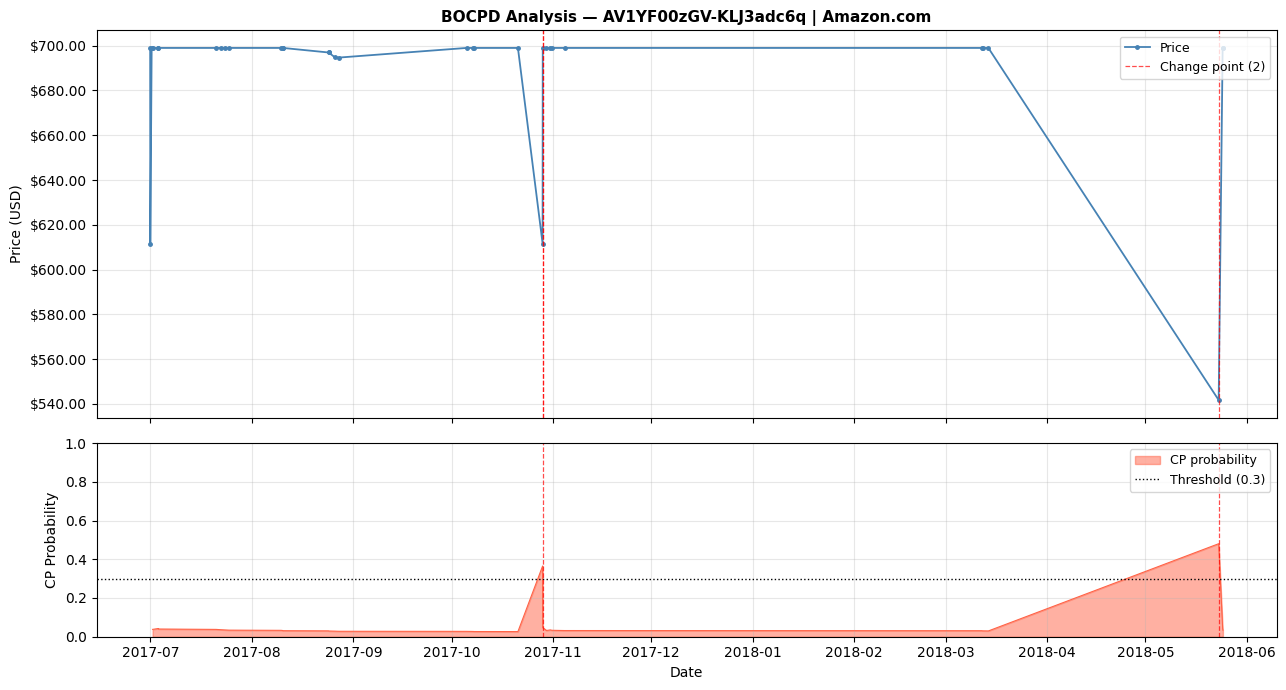

Saved: ../data/figures/bocpd_pair_1.png


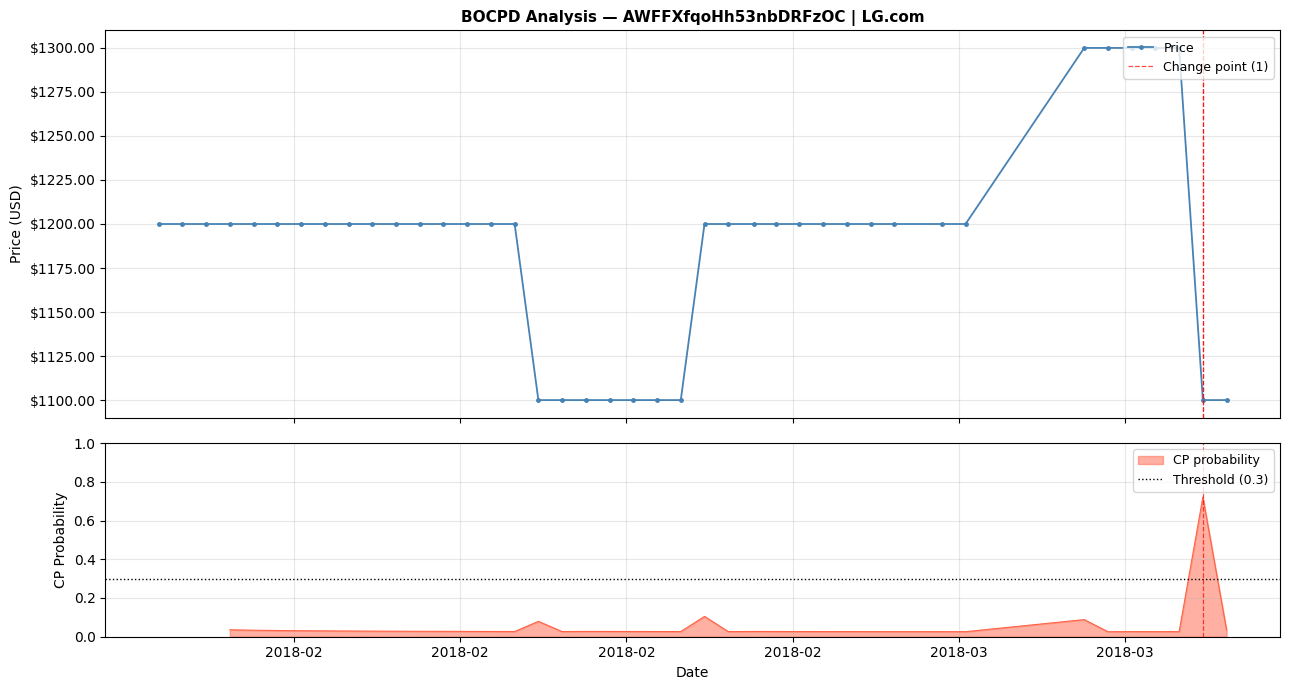

Saved: ../data/figures/bocpd_pair_2.png


In [7]:
for plot_idx, row in cp_per_pair.iterrows():
    pid = row['product_id']
    merch = row['merchant']

    # Feature rows for this pair
    feat_pair = (
        sample_features[
            (sample_features['product_id'] == pid) &
            (sample_features['merchant'] == merch)
        ]
        .sort_values('observed_at')
        .reset_index(drop=True)
    )

    # BOCPD results for this pair
    bocpd_pair = (
        bocpd_results[
            (bocpd_results['product_id'] == pid) &
            (bocpd_results['merchant'] == merch)
        ]
        .sort_values('observed_at')
        .reset_index(drop=True)
    )

    dates_feat = pd.to_datetime(feat_pair['observed_at'])
    dates_bocpd = pd.to_datetime(bocpd_pair['observed_at']) if not bocpd_pair.empty else pd.Series([], dtype='datetime64[ns]')

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                                    gridspec_kw={'height_ratios': [2, 1]})

    # --- Top panel: price ---
    ax1.plot(dates_feat, feat_pair['price'], color='steelblue',
             linewidth=1.3, marker='o', markersize=2.5, label='Price')

    # Sale markers
    if 'is_sale' in feat_pair.columns:
        sale_mask = feat_pair['is_sale'].fillna(False).astype(bool)
        if sale_mask.any():
            ax1.scatter(dates_feat[sale_mask], feat_pair.loc[sale_mask, 'price'],
                        color='gold', zorder=5, s=40, marker='*', label='Sale', edgecolors='k', linewidths=0.4)

    # Detected change point vertical lines
    if not bocpd_pair.empty:
        cp_dates = dates_bocpd[bocpd_pair['is_change_point'].values.astype(bool)]
        for cp_date in cp_dates:
            ax1.axvline(cp_date, color='red', linestyle='--', linewidth=0.9, alpha=0.7)
        if len(cp_dates) > 0:
            ax1.axvline(cp_dates.iloc[0], color='red', linestyle='--',
                        linewidth=0.9, alpha=0.7, label=f'Change point ({len(cp_dates)})')  # legend entry

    ax1.set_ylabel('Price (USD)', fontsize=10)
    short_id = str(pid)[:35] + ('...' if len(str(pid)) > 35 else '')
    ax1.set_title(f'BOCPD Analysis — {short_id} | {merch}', fontsize=11, fontweight='bold')
    ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.2f'))
    ax1.legend(fontsize=9, loc='upper right')
    ax1.grid(alpha=0.3)

    # --- Bottom panel: cp_probability ---
    if not bocpd_pair.empty and 'cp_probability' in bocpd_pair.columns:
        ax2.fill_between(dates_bocpd, bocpd_pair['cp_probability'],
                         alpha=0.5, color='tomato', label='CP probability')
        ax2.plot(dates_bocpd, bocpd_pair['cp_probability'], color='tomato', linewidth=0.8)
        ax2.axhline(config.cp_threshold, color='black', linewidth=1, linestyle=':',
                    label=f'Threshold ({config.cp_threshold})')

        # Vertical lines at CPs
        for cp_date in cp_dates:
            ax2.axvline(cp_date, color='red', linestyle='--', linewidth=0.9, alpha=0.7)
    else:
        ax2.text(0.5, 0.5, 'No BOCPD data for this pair', ha='center', va='center',
                 transform=ax2.transAxes, fontsize=11)

    ax2.set_ylabel('CP Probability', fontsize=10)
    ax2.set_xlabel('Date', fontsize=10)
    ax2.set_ylim(0, 1)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax2.legend(fontsize=9, loc='upper right')
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    save_path = f'../data/figures/bocpd_pair_{plot_idx + 1}.png'
    plt.savefig(save_path, dpi=100, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')

## 5. Summary Table of Detected Change Points

In [8]:
if not bocpd_results.empty:
    cp_rows = bocpd_results[bocpd_results['is_change_point']].copy()

    if cp_rows.empty:
        print('No change points detected in the 20-pair sample.')
    else:
        # Merge back price info
        price_at_cp = sample_features[['product_id', 'merchant', 'observed_at', 'price']].copy()
        price_at_cp['observed_at'] = price_at_cp['observed_at'].astype(str)
        cp_rows['observed_at'] = cp_rows['observed_at'].astype(str)

        cp_summary = cp_rows.merge(
            price_at_cp,
            on=['product_id', 'merchant', 'observed_at'],
            how='left'
        )

        display_cols = [
            c for c in
            ['product_id', 'merchant', 'observed_at', 'cp_probability', 'map_run_length', 'price']
            if c in cp_summary.columns
        ]

        print(f'Total change points detected: {len(cp_summary):,}')
        display(
            cp_summary[display_cols]
            .sort_values('cp_probability', ascending=False)
            .head(30)
            .reset_index(drop=True)
            .style.format({
                'cp_probability': '{:.3f}',
                'price': '${:.2f}'
            })
        )
else:
    print('BOCPD results are empty.')

Total change points detected: 3


,product_id,merchant,observed_at,cp_probability,map_run_length,price
0,AWFFXfqoHh53nbDRFzOC,LG.com,2018-03-11 07:00:00+00:00,0.721,1,$1099.99
1,AV1YF00zGV-KLJ3adc6q,Amazon.com,2018-05-23 10:00:00+00:00,0.480,1,$541.72
2,AV1YF00zGV-KLJ3adc6q,Amazon.com,2017-10-28 20:00:00+00:00,0.365,1,$611.63


## 6. CP Count Distribution Across the 20-Pair Sample

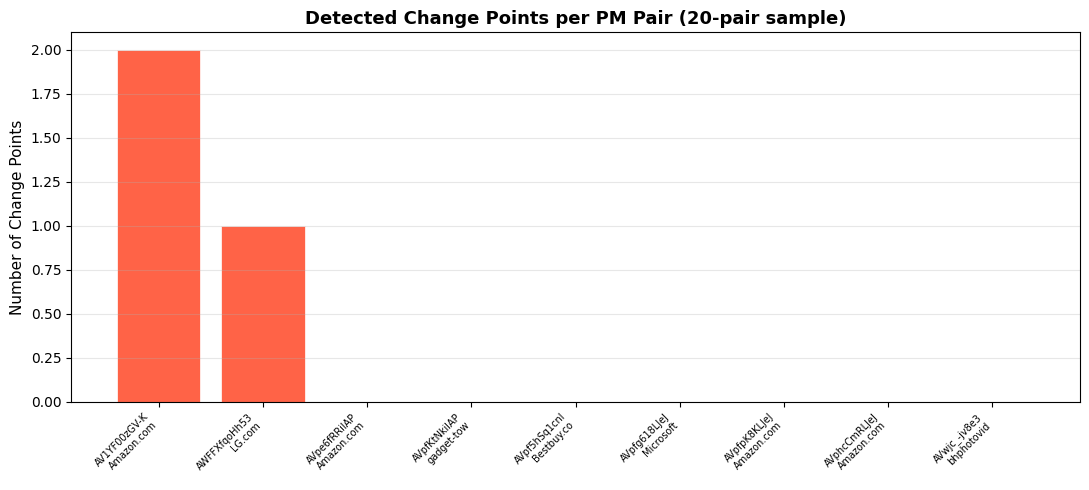

Saved: ../data/figures/bocpd_cp_summary.png


In [9]:
if not bocpd_results.empty:
    cp_counts = (
        bocpd_results
        .groupby(['product_id', 'merchant'])['is_change_point']
        .sum()
        .rename('n_change_points')
        .reset_index()
        .sort_values('n_change_points', ascending=False)
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(
        range(len(cp_counts)),
        cp_counts['n_change_points'],
        color='tomato',
        edgecolor='white',
        linewidth=0.5
    )
    ax.set_xticks(range(len(cp_counts)))
    short_labels = [
        f'{str(r.product_id)[:12]}\n{str(r.merchant)[:10]}'
        for _, r in cp_counts.iterrows()
    ]
    ax.set_xticklabels(short_labels, fontsize=7, rotation=45, ha='right')
    ax.set_ylabel('Number of Change Points', fontsize=11)
    ax.set_title('Detected Change Points per PM Pair (20-pair sample)', fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('../data/figures/bocpd_cp_summary.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Saved: ../data/figures/bocpd_cp_summary.png')
else:
    print('No BOCPD results to plot.')